# Explore recordings for model 1

Model 1 uses one number per window: the peak acceleration on one axis.
This notebook will eb used to determine which axis we want to look at, as well as the window length and peak value to see how the classes differ

1. Load and trim recordings
2. Clipping check
3. Which axis moves most
4. Peak histograms by class for each window length and peak definition

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("../data")
TRIM_S = 5.0                  # drop this much from the start and end of each recording
CLASSES = ["still", "bike", "walk", "run"]
AXES = ["ax", "ay", "az"]
CLIP_G = 15.5                 # close to the ±16 g limit

## 1. Load and trim

In [2]:
def load(path):
    df = pd.read_csv(path)
    df["t"] = (df.t_ms - df.t_ms.iloc[0]) / 1000.0
    end = df.t.iloc[-1]
    return df[(df.t >= TRIM_S) & (df.t <= end - TRIM_S)].reset_index(drop=True)


recs = []   # (name, label, df)
for p in sorted(DATA_DIR.glob("*.csv")):
    label = p.stem.rsplit("_", 1)[0]
    df = load(p)
    recs.append((p.stem, label, df))
    print(f"{p.stem:10s} {label:6s} {len(df):6d} rows  {df.t.iloc[-1] - df.t.iloc[0]:6.1f} s after trim")

missing = [c for c in CLASSES if c not in {r[1] for r in recs}]
if missing:
    print("no recordings yet for:", missing)

bike_01    bike     3458 rows    69.1 s after trim
run_01     run      2670 rows    53.4 s after trim
still_01   still    5702 rows   114.0 s after trim
walk_01    walk    13770 rows   275.4 s after trim


## 2. Clipping check

Any samples near ±16 g mean the peaks are cut off.

In [3]:
for name, label, df in recs:
    clipped = (df[AXES].abs() >= CLIP_G).sum()
    print(f"{name:10s} max |a| per axis: " +
          "  ".join(f"{a} {df[a].abs().max():5.2f}" for a in AXES) +
          f"   samples >= {CLIP_G} g: {int(clipped.sum())}")

bike_01    max |a| per axis: ax  2.07  ay  1.77  az  0.84   samples >= 15.5 g: 0
run_01     max |a| per axis: ax  8.36  ay  5.70  az  9.56   samples >= 15.5 g: 0
still_01   max |a| per axis: ax  0.28  ay  1.09  az  0.28   samples >= 15.5 g: 0
walk_01    max |a| per axis: ax  3.07  ay  3.79  az  3.35   samples >= 15.5 g: 0


## 3. Which axis moves most

Standard deviation per axis for each recording. Model 1 uses the axis with the
largest spread on average (it should be the same axis for every activity).

In [4]:
std = pd.DataFrame({name: df[AXES].std() for name, _, df in recs}).T
std["label"] = [label for _, label, _ in recs]
print(std.round(3))

AXIS = std[AXES].mean().idxmax()
print(f"\nAxis with most variation: {AXIS}")

             ax     ay     az  label
bike_01   0.486  0.584  0.301   bike
run_01    1.388  1.287  0.947    run
still_01  0.016  0.006  0.034  still
walk_01   0.421  0.504  0.403   walk

Axis with most variation: ay


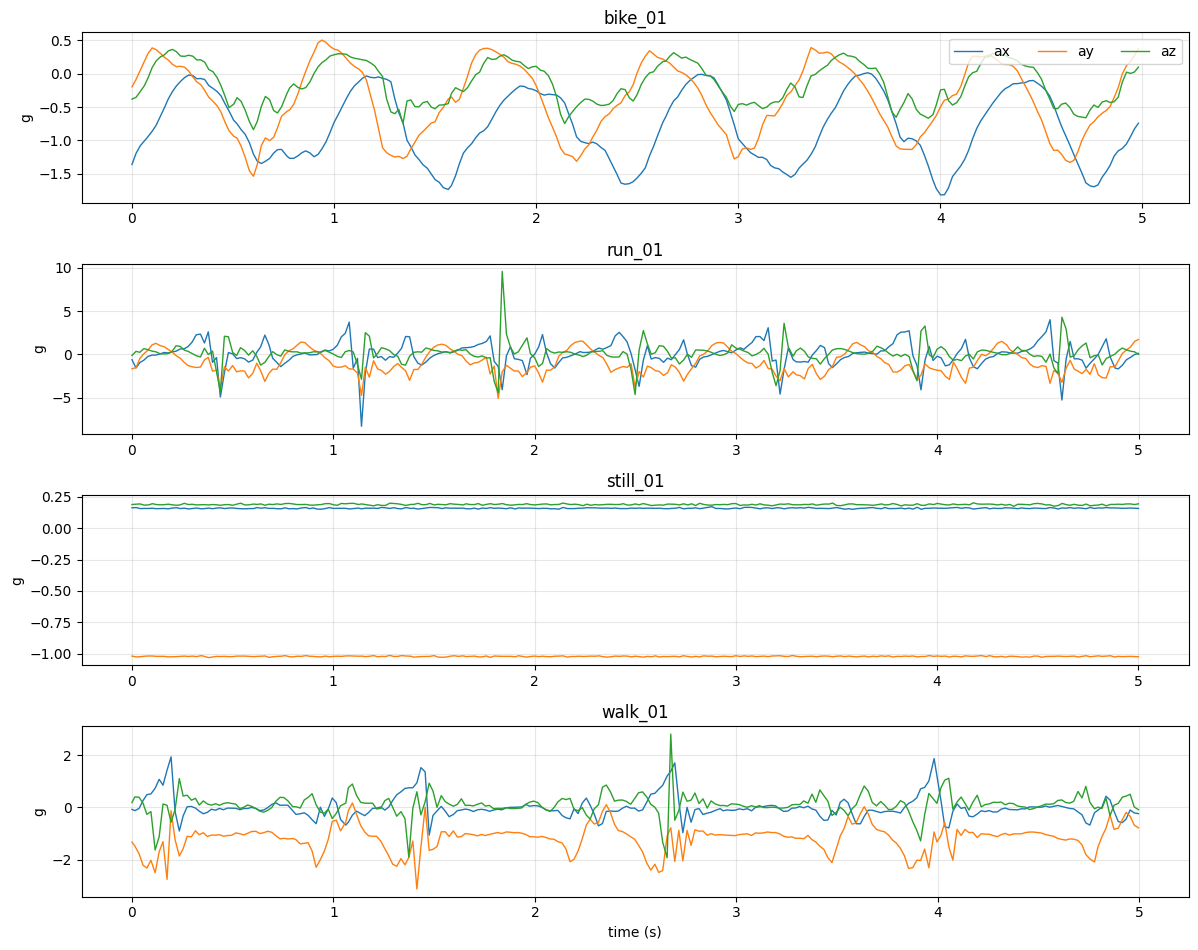

In [5]:
# Signal on each axis, 5 s from the middle of each recording
fig, axs = plt.subplots(len(recs), 1, figsize=(12, 2.4 * len(recs)), squeeze=False)
for ax, (name, label, df) in zip(axs[:, 0], recs):
    mid = df.t.iloc[len(df) // 2]
    seg = df[(df.t >= mid) & (df.t < mid + 5)]
    for a in AXES:
        ax.plot(seg.t - mid, seg[a], lw=1, label=a)
    ax.set_title(name)
    ax.set_ylabel("g")
    ax.grid(alpha=0.3)
axs[0, 0].legend(ncol=3, loc="upper right")
axs[-1, 0].set_xlabel("time (s)")
fig.tight_layout()

## 4. Peak per window

Each recording is cut into windows with 50% overlap. Each window gives one
number, using one of three peak definitions:

- `max_abs`: max |a − mean|
- `range`: max − min
- `p95`: 95th percentile of |a − mean| (ignores single spikes)

In [6]:
WINDOWS_S = [2.0, 3.0, 4.0]
FS = 50


def peak(x, kind):
    d = np.abs(x - x.mean())
    if kind == "max_abs":
        return d.max()
    if kind == "range":
        return x.max() - x.min()
    if kind == "p95":
        return np.percentile(d, 95)
    raise ValueError(kind)


PEAKS = ["max_abs", "range", "p95"]


def windows(df, axis, win_s):
    n = int(win_s * FS)
    step = n // 2
    x = df[axis].to_numpy()
    for i in range(0, len(x) - n + 1, step):
        yield x[i:i + n]


rows = []
for name, label, df in recs:
    for win_s in WINDOWS_S:
        for w in windows(df, AXIS, win_s):
            for kind in PEAKS:
                rows.append({"rec": name, "label": label, "win_s": win_s,
                             "peak": kind, "value": peak(w, kind)})
feats = pd.DataFrame(rows)
feats.groupby(["win_s", "label"]).size().unstack()   # windows per class

label,bike,run,still,walk
win_s,,,,
2.0,204,156,339,822
3.0,135,102,225,546
4.0,99,75,168,408


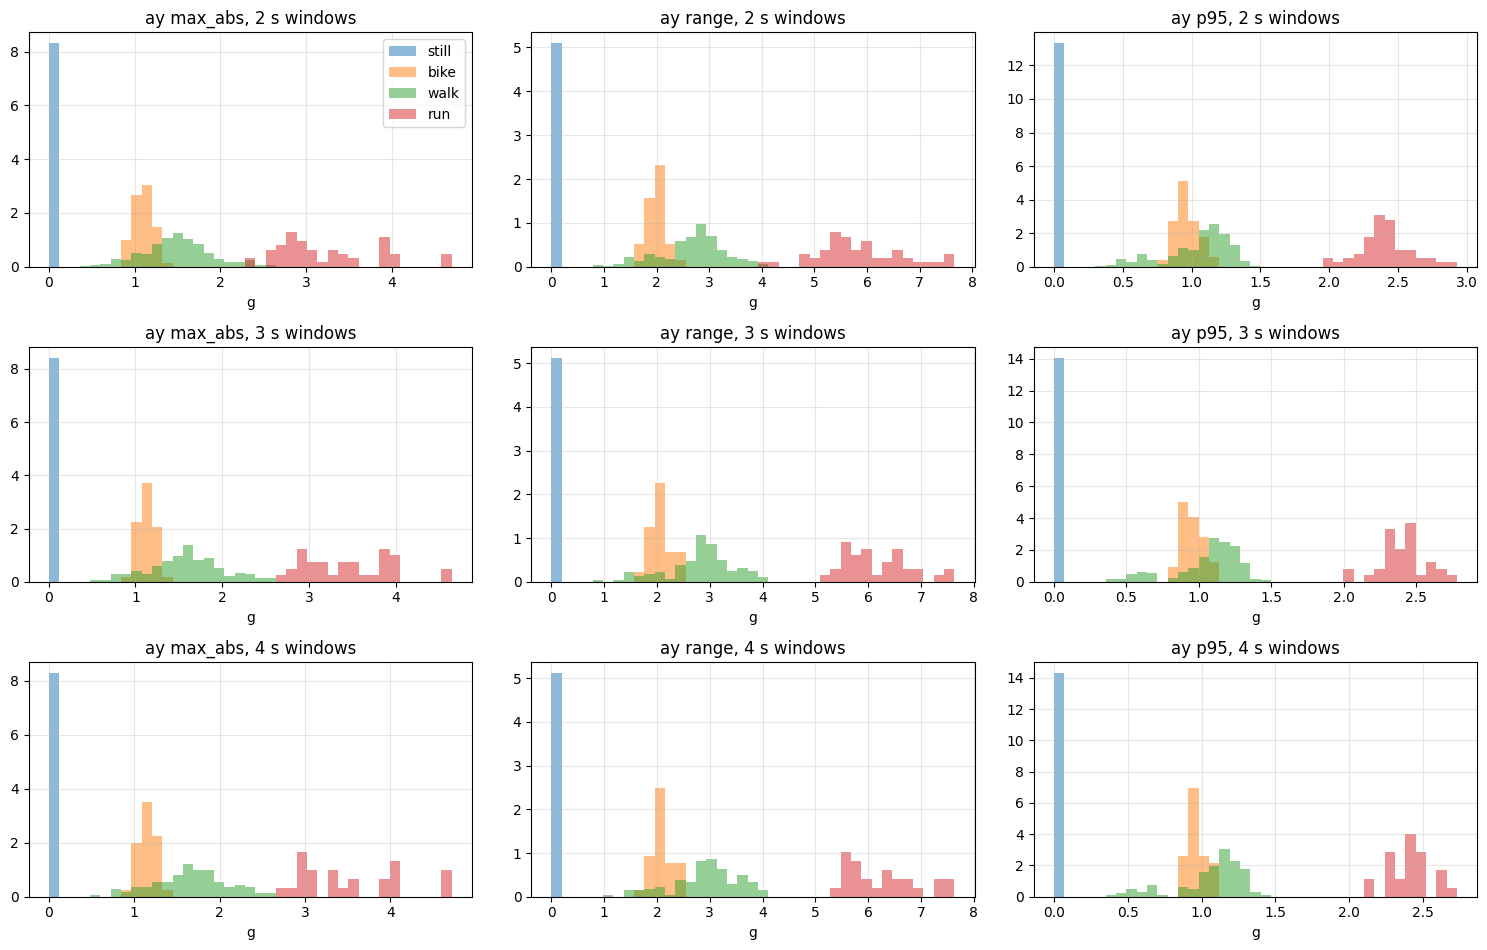

In [7]:
present = [c for c in CLASSES if c in feats.label.unique()]
fig, axs = plt.subplots(len(WINDOWS_S), len(PEAKS), figsize=(15, 3.2 * len(WINDOWS_S)))
for r, win_s in enumerate(WINDOWS_S):
    for c, kind in enumerate(PEAKS):
        ax = axs[r, c]
        sub = feats[(feats.win_s == win_s) & (feats.peak == kind)]
        bins = np.linspace(0, sub.value.max(), 40)
        for label in present:
            ax.hist(sub[sub.label == label].value, bins=bins, alpha=0.5, density=True, label=label)
        ax.set_title(f"{AXIS} {kind}, {win_s:.0f} s windows")
        ax.set_xlabel("g")
        ax.grid(alpha=0.3)
axs[0, 0].legend()
fig.tight_layout()

Summary per class: where each class's peaks sit (10th / 50th / 90th percentile).
Classes separate well when one class's 90th is below the next class's 10th.

In [8]:
(feats.groupby(["win_s", "peak", "label"]).value
      .quantile([0.1, 0.5, 0.9]).unstack().round(2))

0.1   0.5   0.9
win_s peak    label                  
2.0   max_abs bike   0.96  1.09  1.27
              run    2.63  3.05  3.99
              still  0.01  0.01  0.03
              walk   0.99  1.51  1.98
      p95     bike   0.85  0.95  1.08
              run    2.20  2.40  2.66
              still  0.01  0.01  0.02
              walk   0.65  1.11  1.30
      range   bike   1.77  2.00  2.18
              run    5.05  5.69  6.94
              still  0.01  0.02  0.06
              walk   1.84  2.78  3.39
3.0   max_abs bike   1.01  1.13  1.25
              run    2.88  3.43  3.97
              still  0.01  0.02  0.04
              walk   1.01  1.58  2.14
      p95     bike   0.89  0.94  1.06
              run    2.23  2.42  2.63
              still  0.01  0.01  0.02
              walk   0.66  1.12  1.28
      range   bike   1.82  2.03  2.36
              run    5.49  6.02  6.93
              still  0.01  0.03  0.07
              walk   1.88  2.90  3.61
4.0   max_abs bike   1.02  1.13  1.28
              run    2.91  3.37  4.39
              still  0.01  0.02  0.05
              walk   1.07  1.68  2.26
      p95     bike   0.90  0.94  1.06
              run    2.25  2.40  2.61
              still  0.01  0.01  0.02
              walk   0.66  1.14  1.28
      range   bike   1.85  2.06  2.36
              run    5.54  6.17  7.39
              still  0.02  0.03  0.07
              walk   1.94  3.01  3.66

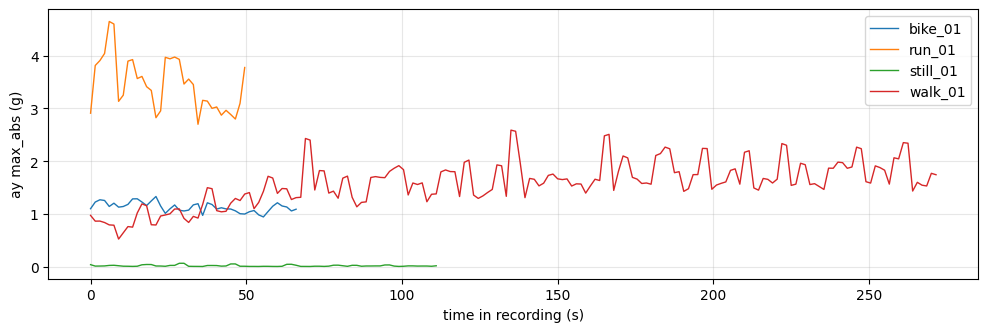

In [9]:
# Steadiness: peak over time within each recording (3 s windows, max_abs)
fig, ax = plt.subplots(figsize=(12, 3.5))
for name, label, df in recs:
    vals = [peak(w, "max_abs") for w in windows(df, AXIS, 3.0)]
    ax.plot(np.arange(len(vals)) * 1.5, vals, lw=1, label=name)
ax.set_xlabel("time in recording (s)")
ax.set_ylabel(f"{AXIS} max_abs (g)")
ax.legend()
ax.grid(alpha=0.3)